# [04] CAS(ME)² — TabR multiclass, LOSO

Melatih TabR official (`third_party/tabular-dl-tabr-official`) untuk mengenali emosi
micro-expression: **negative / others / positive**.

## Rancangan validasi

CAS(ME)² tidak punya struktur pertanyaan q1–q5 seperti dataset anxiety, jadi split
by-question diganti **Leave-One-Subject-Out** — protokol yang dipakai paper RMES.

```
tuning : SEKALI saja pada satu split tetap.
         14x Optuna itu pemborosan dan membuat metrik LOSO bias optimis.

LOSO   : untuk tiap subjek k dari 14 subjek ber-micro:
           test  = seluruh event subjek k
           val   = 20% event dari 13 subjek sisanya, di-group per event_id
                   (semua frame satu event tetap sekelompok) dan stratified per label
           train = sisanya
           hyperparameter dikunci dari hasil tuning

event  : TabR memprediksi per frame -> rata-rata probabilitas per event -> argmax

metrik : kumpulkan prediksi test dari 14 fold, hitung SEKALI di data gabungan.
         BUKAN rata-rata per fold: s19/s29/s38 hanya punya 1 sampel, F1 per fold
         di situ tidak bermakna.
```

## Dua eksperimen

| | train | test | menjawab |
|---|---|---|---|
| **A** | klip GT (`selectedpic`) | klip GT, LOSO | batas atas — kalau spotting sempurna, seberapa baik TabR? |
| **B** | klip GT | klip hasil spotting sendiri | kondisi nyata — seberapa baik sistem utuh saat ground truth tidak diketahui |

Eksperimen B menjawab pertanyaan *"kalau kita tidak tahu ground truth-nya, gimana?"*.
Untuk interval TP emosinya diketahui sehingga akurasi bisa dihitung; untuk FP tidak ada
emosi sebenarnya, jadi yang dilaporkan hanya sebaran prediksinya.

In [1]:
from __future__ import annotations

import copy
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import Markdown, display
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid')

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'casme2':
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
if str(PROJECT_ROOT / 'casme2') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'casme2'))

TABR_ROOT = PROJECT_ROOT / 'third_party' / 'tabular-dl-tabr-official'
os.environ['PROJECT_DIR'] = str(TABR_ROOT)
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')
if str(TABR_ROOT) not in sys.path:
    sys.path.append(str(TABR_ROOT))

import lib
import bin.go
import bin.tabr

import casme2_lib as cl

# Harus sama dengan [01] dan [03] supaya membaca file fitur yang benar.
config = cl.Casme2Config(project_root=PROJECT_ROOT, face_alignment=True)

DATA_ROOT = TABR_ROOT / 'data'
EXP_ROOT = TABR_ROOT / 'exp' / 'tabr'
BASE_TUNING_TOML = EXP_ROOT / 'convat_apex_anxiety' / '0-tuning.toml'
RESULT_ROOT = config.output_root / 'tabr'
cl.ensure_dir(RESULT_ROOT)

GT_FEATURE_PATH = config.feature_root / 'poc_abs_gt.xlsx'
SPOTTED_FEATURE_PATH = config.feature_root / 'poc_abs_spotted.xlsx'

DATASET_PREFIX = 'casme2_micro_emotion' + ('_aligned' if config.face_alignment else '')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f'TABR_ROOT = {TABR_ROOT}')
print(f'device    = {device}')
print(f'classes   = {cl.EMOTION_CLASSES}')
print(f'features  = {config.feature_root}')

TABR_ROOT = /home/ryuko/skripsi/Skripsi/Convat-1st/third_party/tabular-dl-tabr-official
device    = cuda
classes   = ['negative', 'others', 'positive']
features  = /home/ryuko/skripsi/Skripsi/Convat-1st/output/casme2/features_aligned


In [2]:
META_FIELDS = [
    'source', 'status', 'participant', 'subject', 'video_code', 'clip', 'event_clip',
    'event_no', 'label', 'self_emotion', 'onset_img', 'apex_img', 'offset_img',
    'matched_clip_name', 'matched_iou', 'event_id', 'frame', 'target',
]

# --- kontrol eksperimen ---
# Klip FP tidak punya emosi sebenarnya, jadi tidak bisa dipakai melatih pengenal emosi.
# Set True hanya kalau ingin menambah kelas keempat `non_me` (perhatikan ketimpangannya).
INCLUDE_FP_IN_TRAINING = False


def load_features(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f'Jalankan [03] dulu: {path}')
    df = pd.read_excel(path)
    if 'event_id' not in df.columns:
        raise KeyError(f'Kolom event_id tidak ada di {path}')
    return df


df_gt = load_features(GT_FEATURE_PATH)
df_gt = df_gt[df_gt['label'].isin(cl.LABEL_MAP)].copy()
df_gt['target'] = df_gt['label'].map(cl.LABEL_MAP).astype(int)

FEATURE_COLS = [c for c in df_gt.columns if c not in META_FIELDS]

print(f'Baris       : {len(df_gt)}')
print(f'Event       : {df_gt["event_id"].nunique()}')
print(f'Subjek      : {df_gt["participant"].nunique()}')
print(f'Kolom fitur : {len(FEATURE_COLS)}')
print()
event_table = df_gt.drop_duplicates('event_id')
print(pd.crosstab(event_table['participant'], event_table['label'], margins=True).to_string())

Baris       : 717
Event       : 57
Subjek      : 14
Kolom fitur : 392

label        negative  others  positive  All
participant                                 
s15                 1       0         1    2
s16                 2       1         5    8
s19                 1       0         0    1
s23                 3       0         0    3
s24                 0       5         3    8
s25                 3       1         0    4
s27                 3       6         2   11
s29                 1       0         0    1
s30                 1       1         0    2
s31                 1       4         1    6
s32                 3       2         1    6
s35                 1       1         0    2
s37                 1       0         1    2
s38                 0       0         1    1
All                21      21        15   57


## Utilitas split dan export dataset

`export_official_dataset()` di notebook anxiety menulis `task_type: 'binclass'` secara
hardcoded. Di sini dibuat versi sendiri yang menulis `'multiclass'` — TabR official
mendukungnya lewat `lib/data.py`.

In [3]:
def split_train_val(df: pd.DataFrame, val_size: float = 0.2, seed: int = 0):
    """Bagi event (bukan frame) jadi train/val, stratified per label.

    Grouping per `event_id` mencegah frame dari event yang sama bocor ke dua sisi.
    """
    events = df.drop_duplicates('event_id')[['event_id', 'target']].reset_index(drop=True)
    counts = events['target'].value_counts()
    stratify = events['target'] if (counts.min() >= 2 and len(counts) > 1) else None

    splitter = StratifiedShuffleSplit(n_splits=1, test_size=val_size, random_state=seed)
    if stratify is not None:
        train_idx, val_idx = next(splitter.split(events, stratify))
    else:
        rng = np.random.default_rng(seed)
        order = rng.permutation(len(events))
        cut = max(1, int(len(events) * val_size))
        val_idx, train_idx = order[:cut], order[cut:]

    val_events = set(events.loc[val_idx, 'event_id'])
    train_events = set(events.loc[train_idx, 'event_id'])
    return df[df['event_id'].isin(train_events)].copy(), df[df['event_id'].isin(val_events)].copy()


def export_dataset(df_train, df_val, df_test, feature_cols, dataset_name):
    """Tulis dataset ke format TabR official. task_type = multiclass."""
    out_dir = DATA_ROOT / dataset_name
    out_dir.mkdir(parents=True, exist_ok=True)

    imputer = SimpleImputer(strategy='mean')
    scaler = StandardScaler()
    X_train = scaler.fit_transform(imputer.fit_transform(df_train[feature_cols])).astype(np.float32)
    X_val = scaler.transform(imputer.transform(df_val[feature_cols])).astype(np.float32)
    X_test = scaler.transform(imputer.transform(df_test[feature_cols])).astype(np.float32)

    np.save(out_dir / 'X_num_train.npy', X_train)
    np.save(out_dir / 'X_num_val.npy', X_val)
    np.save(out_dir / 'X_num_test.npy', X_test)
    np.save(out_dir / 'Y_train.npy', df_train['target'].to_numpy(dtype=np.int64))
    np.save(out_dir / 'Y_val.npy', df_val['target'].to_numpy(dtype=np.int64))
    np.save(out_dir / 'Y_test.npy', df_test['target'].to_numpy(dtype=np.int64))

    (out_dir / 'READY').write_text('')
    (out_dir / 'info.json').write_text(json.dumps({
        'task_type': 'multiclass',                 # <- beda dari notebook anxiety
        'n_classes': len(cl.EMOTION_CLASSES),
        'name': dataset_name,
        'id': dataset_name,
    }, indent=2))
    (out_dir / 'feature_cols.json').write_text(json.dumps(feature_cols, indent=2))
    df_train.drop(columns=feature_cols).to_csv(out_dir / 'train_split.csv', index=False)
    df_val.drop(columns=feature_cols).to_csv(out_dir / 'val_split.csv', index=False)
    df_test.drop(columns=feature_cols).to_csv(out_dir / 'test_split.csv', index=False)

    return {
        'dataset_dir': out_dir,
        'n_train': len(df_train), 'n_val': len(df_val), 'n_test': len(df_test),
        'events_train': df_train['event_id'].nunique(),
        'events_val': df_val['event_id'].nunique(),
        'events_test': df_test['event_id'].nunique(),
    }


def prepare_config(dataset_name: str, exp_name: str, tuning: bool = True) -> Path:
    base = lib.load_config(BASE_TUNING_TOML)
    cfg = copy.deepcopy(base)
    cfg['space']['data']['path'] = f':data/{dataset_name}'
    exp_dir = EXP_ROOT / exp_name
    exp_dir.mkdir(parents=True, exist_ok=True)
    toml_path = exp_dir / ('0-tuning.toml' if tuning else '0.toml')
    lib.dump_config(cfg, toml_path)
    return toml_path

## Tahap 1 — tuning sekali

Satu split tetap: subjek diurutkan lalu dibagi kira-kira 70/15/15. Hyperparameter
terbaik dari sini dipakai untuk seluruh 14 fold LOSO.

In [4]:
subjects = sorted(df_gt['participant'].unique().tolist(), key=cl.natural_sort_key)
n = len(subjects)
tune_test_subjects = subjects[int(n * 0.85):]
tune_val_subjects = subjects[int(n * 0.70):int(n * 0.85)]
tune_train_subjects = subjects[:int(n * 0.70)]

df_tune_train = df_gt[df_gt['participant'].isin(tune_train_subjects)].copy()
df_tune_val = df_gt[df_gt['participant'].isin(tune_val_subjects)].copy()
df_tune_test = df_gt[df_gt['participant'].isin(tune_test_subjects)].copy()

TUNE_DATASET = f'{DATASET_PREFIX}_tune'
info = export_dataset(df_tune_train, df_tune_val, df_tune_test, FEATURE_COLS, TUNE_DATASET)

print(f'train subjek: {tune_train_subjects}')
print(f'val   subjek: {tune_val_subjects}')
print(f'test  subjek: {tune_test_subjects}')
print(info)
print(f'\nDataset tuning: {info["dataset_dir"]}')

train subjek: ['s15', 's16', 's19', 's23', 's24', 's25', 's27', 's29', 's30']
val   subjek: ['s31', 's32']
test  subjek: ['s35', 's37', 's38']
{'dataset_dir': PosixPath('/home/ryuko/skripsi/Skripsi/Convat-1st/third_party/tabular-dl-tabr-official/data/casme2_micro_emotion_aligned_tune'), 'n_train': 503, 'n_val': 154, 'n_test': 60, 'events_train': 40, 'events_val': 12, 'events_test': 5}

Dataset tuning: /home/ryuko/skripsi/Skripsi/Convat-1st/third_party/tabular-dl-tabr-official/data/casme2_micro_emotion_aligned_tune


In [5]:
# Jalankan tuning TabR official. Cukup sekali; hasilnya dipakai ulang oleh semua fold.
N_EVAL_SEEDS = 15
N_ENSEMBLES = 3
ENSEMBLE_SIZE = 5

TUNE_EXP = f'{DATASET_PREFIX}_tune'
tuning_toml = prepare_config(TUNE_DATASET, TUNE_EXP, tuning=True)
print(f'Config tuning: {tuning_toml}')
print('Menjalankan bin.go (tuning + evaluasi multi-seed) ... bisa lama')

bin.go.main(
    tuning_toml,
    n_seeds=N_EVAL_SEEDS,
    n_ensembles=N_ENSEMBLES,
    ensemble_size=ENSEMBLE_SIZE,
    continue_=True,
    force=False,
)
print('Tuning selesai.')

2026-09-02 21:06:33.111 | INFO     | lib.util:start:130 - Creating the output
[I 2026-09-02 21:06:33,208] A new study created in memory with name: no-name-78d7a244-b36a-4209-987e-af22f7362e19


Config tuning: /home/ryuko/skripsi/Skripsi/Convat-1st/third_party/tabular-dl-tabr-official/exp/tabr/casme2_micro_emotion_aligned_tune/0-tuning.toml
Menjalankan bin.go (tuning + evaluasi multi-seed) ... bisa lama
[>>>] exp/tabr/casme2_micro_emotion_aligned_tune/0-tuning | 2026-09-02 21:06:33.111431
--------------------------------------------------------------------------------
{'seed': 72,
 'function': 'bin.tabr.main',
 'space': {'seed': 72,
           'batch_size': 128,
           'patience': 6,
           'n_epochs': inf,
           'context_size': ['_tune_', 'int', 4, 16],
           'data': {'seed': 72,
                    'cache': True,
                    'path': ':data/casme2_micro_emotion_aligned_tune',
                    'num_policy': None,
                    'cat_policy': None,
                    'y_policy': None},
           'model': {'num_embeddings': None,
                     'd_main': ['_tune_', 'int', 96, 256],
                     'context_dropout': ['_tune_', 'unif

  0%|          | 0/15 [00:00<?, ?it/s]

2026-09-02 21:06:33.217 | INFO     | lib.util:start:130 - Creating the output


[>>>] /tmp/tmpk22dbkbg_trial_0/output | 2026-09-02 21:06:33.217070


...

(val) 0.338 (test) 0.300 (loss) 0.62952

[...] exp/tabr/casme2_micro_emotion_aligned_tune/0-evaluation/14 | 0:00:00.389581


Epoch 6: 100%|██████████| 4/4 [00:00<00:00, 170.50it/s]


(val) 0.331 (test) 0.317 (loss) 0.63149

[...] exp/tabr/casme2_micro_emotion_aligned_tune/0-evaluation/14 | 0:00:00.427230


Epoch 7: 100%|██████████| 4/4 [00:00<00:00, 181.47it/s]


(val) 0.338 (test) 0.300 (loss) 0.54157

--------------------------------------------------------------------------------
{'function': 'bin.tabr.main',
 'gpus': ['NVIDIA GeForce RTX 3050 Laptop GPU'],
 'n_parameters': 957955,
 'best_epoch': 0,
 'scores': {'train': 0.7037773359840954,
            'val': 0.38961038961038963,
            'test': 0.38333333333333336},
 'time': '0:00:00.462614'}
--------------------------------------------------------------------------------
[<<<] exp/tabr/casme2_micro_emotion_aligned_tune/0-evaluation/14 | 2026-09-02 21:07:01.358860

--------------------------------------------------------------------------------
{'function': 'bin.ensemble.main',
 'gpus': [],
 'scores': {'train': 0.8747514910536779,
            'val': 0.2987012987012987,
            'test': 0.2833333333333333}}
--------------------------------------------------------------------------------
[<<<] exp/tabr/casme2_micro_emotion_aligned_tune/0-ensemble-5/0 | 2026-09-02 21:07:01.432840

------

In [6]:
def load_best_config(exp_name: str) -> tuple[dict, int]:
    """Ambil config seed terbaik berdasarkan skor validasi."""
    eval_dir = EXP_ROOT / exp_name / '0-evaluation'
    best = None
    for run_dir in sorted([p for p in eval_dir.iterdir() if p.is_dir() and p.name.isdigit()]):
        report_path = run_dir / 'report.json'
        if not report_path.exists():
            continue
        report = json.loads(report_path.read_text())
        score = report['metrics']['val']['score']
        if best is None or score > best[0]:
            best = (score, int(run_dir.name), report)
    if best is None:
        raise FileNotFoundError(f'Tidak ada report.json di {eval_dir}')

    _score, seed, report = best
    seed_toml = EXP_ROOT / exp_name / f'{seed}.toml'
    if seed_toml.exists():
        return lib.load_config(seed_toml), seed
    return report['config'], seed


best_config, best_seed = load_best_config(TUNE_EXP)
print(f'Seed terbaik: {best_seed}')
print(json.dumps(best_config.get('model', {}), indent=2)[:600])

Seed terbaik: 8
{
  "num_embeddings": null,
  "d_main": 256,
  "context_dropout": 0.33272391737689205,
  "d_multiplier": 2.0,
  "encoder_n_blocks": 1,
  "predictor_n_blocks": 1,
  "mixer_normalization": "auto",
  "dropout0": 0.38833054989222776,
  "dropout1": 0.13470987396597167,
  "normalization": "LayerNorm",
  "activation": "ReLU"
}


## Tahap 2 — LOSO 14 fold

Setiap fold: satu subjek jadi test, sisanya train/val. Hyperparameter dikunci.

In [7]:
def run_fold(df_all: pd.DataFrame, test_subject: str, fold_no: int) -> pd.DataFrame:
    df_test = df_all[df_all['participant'] == test_subject].copy()
    df_rest = df_all[df_all['participant'] != test_subject].copy()
    df_train, df_val = split_train_val(df_rest, val_size=0.2, seed=fold_no)

    dataset_name = f'{DATASET_PREFIX}_loso_{test_subject}'
    exp_name = dataset_name
    info = export_dataset(df_train, df_val, df_test, FEATURE_COLS, dataset_name)

    # Hyperparameter dikunci -> jalankan satu run langsung lewat bin.tabr,
    # bukan bin.go (bin.go selalu melakukan tuning ulang).
    cfg = copy.deepcopy(best_config)
    cfg['data']['path'] = f':data/{dataset_name}'
    cfg['seed'] = int(cfg.get('seed', 0))

    output_dir = EXP_ROOT / exp_name / '0'
    output_dir.parent.mkdir(parents=True, exist_ok=True)
    lib.dump_config(cfg, EXP_ROOT / exp_name / '0.toml')

    bin.tabr.main(cfg, output_dir, force=True)

    predictions = lib.load_predictions(output_dir)['test']
    y_pred_frame = predictions.argmax(axis=1) if predictions.ndim > 1 else predictions

    out = df_test[['event_id', 'participant', 'clip', 'event_clip', 'label', 'target']].copy()
    out['pred_frame'] = y_pred_frame
    for class_idx, class_name in enumerate(cl.EMOTION_CLASSES):
        out[f'prob_{class_name}'] = predictions[:, class_idx] if predictions.ndim > 1 else np.nan
    out['fold'] = fold_no
    out['test_subject'] = test_subject
    return out


frame_predictions = []
for fold_no, subject in enumerate(subjects, start=1):
    print(f'--- fold {fold_no}/{len(subjects)}: test = {subject} ---', flush=True)
    try:
        frame_predictions.append(run_fold(df_gt, subject, fold_no))
    except Exception as exc:
        print(f'  fold {subject} gagal: {exc}')

frame_pred_df = pd.concat(frame_predictions, ignore_index=True)
frame_pred_df.to_excel(RESULT_ROOT / 'loso_frame_predictions.xlsx', index=False)
print(f'\nPrediksi frame: {len(frame_pred_df)} baris dari {frame_pred_df["fold"].nunique()} fold')

--- fold 1/14: test = s15 ---


2026-09-02 21:07:01.520 | INFO     | lib.util:start:130 - Creating the output
2026-09-02 21:07:01.535 | INFO     | lib.data:build_dataset:346 - Building dataset (path: /home/ryuko/skripsi/Skripsi/Convat-1st/third_party/tabular-dl-tabr-official/data/casme2_micro_emotion_aligned_loso_s15)
2026-09-02 21:07:01.543 | INFO     | bin.tabr:main:349 - n_parameters = 957955


[>>>] exp/tabr/casme2_micro_emotion_aligned_loso_s15/0 | 2026-09-02 21:07:01.520440
--------------------------------------------------------------------------------
{'seed': 8,
 'data': {'seed': 72,
          'cache': True,
          'path': ':data/casme2_micro_emotion_aligned_loso_s15',
          'num_policy': None,
          'cat_policy': None,
          'y_policy': None},
 'model': {'num_embeddings': None,
           'd_main': 256,
           'context_dropout': 0.33272391737689205,
           'd_multiplier': 2.0,
           'encoder_n_blocks': 1,
           'predictor_n_blocks': 1,
           'mixer_normalization': 'auto',
           'dropout0': 0.38833054989222776,
           'dropout1': 0.13470987396597167,
           'normalization': 'LayerNorm',
           'activation': 'ReLU'},
 'context_size': 11,
 'optimizer': {'type': 'AdamW',
               'lr': 0.0001240336417057033,
               'weight_decay': 0.00040411493523403845},
 'batch_size': 128,
 'patience': 6,
 'n_epochs': i

Epoch 0: 100%|██████████| 5/5 [00:00<00:00, 28.90it/s]
/home/ryuko/skripsi/Skripsi/Convat-1st/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/ryuko/skripsi/Skripsi/Convat-1st/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/ryuko/skripsi/Skripsi/Convat-1st/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to cont

  fold s15 gagal: y_true and y_prob contain different number of classes: 2 vs 3. Please provide the true labels explicitly through the labels argument. Classes found in y_true: [0 2]
--- fold 2/14: test = s16 ---


...

  fold s37 gagal: y_true and y_prob contain different number of classes: 2 vs 3. Please provide the true labels explicitly through the labels argument. Classes found in y_true: [0 2]
--- fold 14/14: test = s38 ---


2026-09-02 21:07:08.294 | INFO     | lib.util:start:130 - Creating the output
2026-09-02 21:07:08.308 | INFO     | lib.data:build_dataset:346 - Building dataset (path: /home/ryuko/skripsi/Skripsi/Convat-1st/third_party/tabular-dl-tabr-official/data/casme2_micro_emotion_aligned_loso_s38)
2026-09-02 21:07:08.317 | INFO     | bin.tabr:main:349 - n_parameters = 957955


[>>>] exp/tabr/casme2_micro_emotion_aligned_loso_s38/0 | 2026-09-02 21:07:08.293990
--------------------------------------------------------------------------------
{'seed': 8,
 'data': {'seed': 72,
          'cache': True,
          'path': ':data/casme2_micro_emotion_aligned_loso_s38',
          'num_policy': None,
          'cat_policy': None,
          'y_policy': None},
 'model': {'num_embeddings': None,
           'd_main': 256,
           'context_dropout': 0.33272391737689205,
           'd_multiplier': 2.0,
           'encoder_n_blocks': 1,
           'predictor_n_blocks': 1,
           'mixer_normalization': 'auto',
           'dropout0': 0.38833054989222776,
           'dropout1': 0.13470987396597167,
           'normalization': 'LayerNorm',
           'activation': 'ReLU'},
 'context_size': 11,
 'optimizer': {'type': 'AdamW',
               'lr': 0.0001240336417057033,
               'weight_decay': 0.00040411493523403845},
 'batch_size': 128,
 'patience': 6,
 'n_epochs': i

Epoch 0: 100%|██████████| 5/5 [00:00<00:00, 27.06it/s]
/home/ryuko/skripsi/Skripsi/Convat-1st/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/ryuko/skripsi/Skripsi/Convat-1st/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/ryuko/skripsi/Skripsi/Convat-1st/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to cont

  fold s38 gagal: y_true contains only one label (2). Please provide the list of all expected class labels explicitly through the labels argument.

Prediksi frame: 389 baris dari 4 fold


## Tahap 3 — agregasi ke level event

Probabilitas per frame dirata-rata dalam satu event, lalu diambil argmax.

In [8]:
prob_cols = [f'prob_{name}' for name in cl.EMOTION_CLASSES]

event_pred = (
    frame_pred_df
    .groupby(['event_id', 'participant', 'clip', 'event_clip', 'label', 'target', 'test_subject', 'fold'],
             as_index=False)[prob_cols]
    .mean()
)
event_pred['pred_target'] = event_pred[prob_cols].to_numpy().argmax(axis=1)
event_pred['pred_label'] = event_pred['pred_target'].map(dict(enumerate(cl.EMOTION_CLASSES)))
event_pred['benar'] = event_pred['pred_target'] == event_pred['target']
event_pred['n_frames'] = frame_pred_df.groupby('event_id').size().reindex(event_pred['event_id']).to_numpy()

event_pred.to_excel(RESULT_ROOT / 'loso_event_predictions.xlsx', index=False)

print(f'Event dievaluasi: {len(event_pred)}')
print(f'Benar           : {int(event_pred["benar"].sum())}')
event_pred[['participant', 'event_clip', 'label', 'pred_label', 'benar']].head(10)

Event dievaluasi: 31
Benar           : 7


,participant,event_clip,label,pred_label,benar
0,s16,disgust1_3,negative,others,False
1,s16,disgust2_3,negative,others,False
2,s16,happy1_1,positive,others,False
3,s16,happy3_2,positive,others,False
4,s16,happy3_8,positive,others,False
5,s16,happy3_9,positive,others,False
6,s16,happy4_3,others,others,True
7,s16,happy4_4,positive,others,False
8,s27,disgust1_2,negative,positive,False
9,s27,disgust2_1,negative,negative,True


## Hasil Eksperimen A — GT dilatih dan diuji, LOSO

Metrik dihitung sekali di seluruh prediksi test gabungan (bukan rata-rata per fold).

In [9]:
y_true = event_pred['target'].to_numpy()
y_pred = event_pred['pred_target'].to_numpy()

metrics_a = {
    'accuracy': accuracy_score(y_true, y_pred),
    'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
    'f1_macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
    'f1_weighted': f1_score(y_true, y_pred, average='weighted', zero_division=0),
    'n_event': len(event_pred),
}
pd.DataFrame([metrics_a]).to_excel(RESULT_ROOT / 'loso_metrics.xlsx', index=False)

print('=' * 52)
print('  EKSPERIMEN A — TabR emosi micro, LOSO 14 subjek')
print('=' * 52)
for key, value in metrics_a.items():
    print(f'  {key:20s}: {value:.4f}' if isinstance(value, float) else f'  {key:20s}: {value}')
print('=' * 52)
print()
print(classification_report(y_true, y_pred, target_names=cl.EMOTION_CLASSES, zero_division=0))

  EKSPERIMEN A — TabR emosi micro, LOSO 14 subjek
  accuracy            : 0.2258
  balanced_accuracy   : 0.2251
  f1_macro            : 0.2152
  f1_weighted         : 0.2172
  n_event             : 31

              precision    recall  f1-score   support

    negative       0.21      0.33      0.26         9
      others       0.23      0.23      0.23        13
    positive       0.25      0.11      0.15         9

    accuracy                           0.23        31
   macro avg       0.23      0.23      0.22        31
weighted avg       0.23      0.23      0.22        31



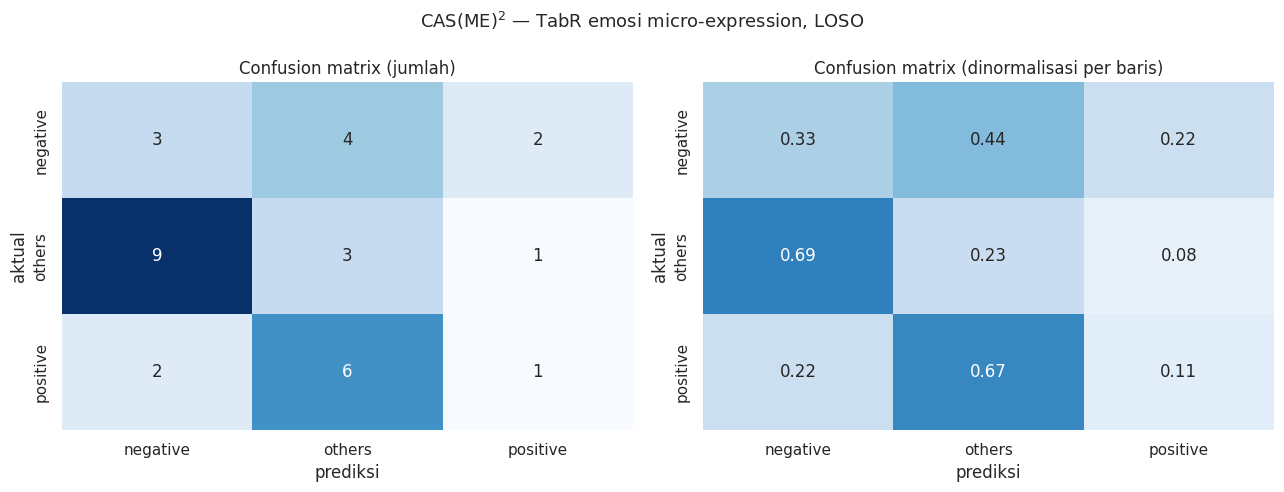

,test_subject,n_event,n_benar,akurasi
0,s16,8,1,0.125000
1,s27,11,3,0.272727
2,s31,6,2,0.333333
3,s32,6,1,0.166667


In [10]:
cm = confusion_matrix(y_true, y_pred, labels=range(len(cl.EMOTION_CLASSES)))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=cl.EMOTION_CLASSES, yticklabels=cl.EMOTION_CLASSES, ax=axes[0])
axes[0].set_xlabel('prediksi'); axes[0].set_ylabel('aktual')
axes[0].set_title('Confusion matrix (jumlah)')

cm_norm = cm.astype(float) / np.clip(cm.sum(axis=1, keepdims=True), 1, None)
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', cbar=False, vmin=0, vmax=1,
            xticklabels=cl.EMOTION_CLASSES, yticklabels=cl.EMOTION_CLASSES, ax=axes[1])
axes[1].set_xlabel('prediksi'); axes[1].set_ylabel('aktual')
axes[1].set_title('Confusion matrix (dinormalisasi per baris)')

fig.suptitle('CAS(ME)$^2$ — TabR emosi micro-expression, LOSO', fontsize=13)
fig.tight_layout()
fig.savefig(RESULT_ROOT / 'loso_confusion_matrix.png', dpi=200, bbox_inches='tight')
plt.show()

per_subject = event_pred.groupby('test_subject').agg(
    n_event=('benar', 'size'), n_benar=('benar', 'sum')).reset_index()
per_subject['akurasi'] = per_subject['n_benar'] / per_subject['n_event']
per_subject.to_excel(RESULT_ROOT / 'loso_per_subject.xlsx', index=False)
per_subject

## Hasil Eksperimen B — diuji pada hasil spotting sendiri

Model dilatih pada seluruh klip GT, lalu diterapkan ke klip hasil spotting.
Ini kondisi nyata: saat sistem berjalan sendiri, ground truth tidak diketahui.

- interval **TP** → emosi sebenarnya diketahui, akurasi bisa dihitung
- interval **FP** → tidak ada emosi sebenarnya, hanya sebaran prediksi yang dilaporkan

In [12]:
df_spotted = load_features(SPOTTED_FEATURE_PATH)

if not INCLUDE_FP_IN_TRAINING:
    print('INCLUDE_FP_IN_TRAINING = False -> klip FP hanya diprediksi, tidak dipakai melatih.')

# Latih pada SELURUH klip GT, uji pada klip spotting.
df_spotted_eval = df_spotted.copy()

# Klip FP berlabel `non_me` -- tidak punya emosi sebenarnya, jadi tidak ada di LABEL_MAP.
# TabR tetap menghitung metrik internal atas Y_test, dan label di luar {0,1,2} membuat
# jumlah kelas y_true tidak cocok dengan jumlah kolom probabilitas -> ValueError di log_loss.
# Karena itu baris tanpa label sebenarnya diberi target boneka 0. Nilai ini TIDAK PERNAH
# dipakai untuk mengevaluasi apa pun: metrik test bawaan TabR diabaikan, dan metrik
# eksperimen B dihitung sendiri di sel berikutnya, hanya dari interval TP.
df_spotted_eval['has_true_label'] = df_spotted_eval['label'].isin(cl.LABEL_MAP)
df_spotted_eval['target'] = (
    df_spotted_eval['label'].map(cl.LABEL_MAP).fillna(0).astype(int)
)

n_dummy = int((~df_spotted_eval['has_true_label']).sum())
print(f'Baris tanpa label emosi (FP, target boneka): {n_dummy} dari {len(df_spotted_eval)}')
print('Metrik test bawaan TabR untuk eksperimen B tidak bermakna -- diabaikan.')

df_train_b, df_val_b = split_train_val(df_gt, val_size=0.2, seed=99)
DATASET_B = f'{DATASET_PREFIX}_spotted'
info_b = export_dataset(df_train_b, df_val_b, df_spotted_eval, FEATURE_COLS, DATASET_B)

cfg_b = copy.deepcopy(best_config)
cfg_b['data']['path'] = f':data/{DATASET_B}'
cfg_b['seed'] = int(cfg_b.get('seed', 0))

output_dir_b = EXP_ROOT / DATASET_B / '0'
output_dir_b.parent.mkdir(parents=True, exist_ok=True)
lib.dump_config(cfg_b, EXP_ROOT / DATASET_B / '0.toml')

bin.tabr.main(cfg_b, output_dir_b, force=True)

pred_b = lib.load_predictions(output_dir_b)['test']
out_b = df_spotted_eval[['event_id', 'participant', 'clip', 'event_clip',
                         'status', 'label', 'has_true_label', 'matched_iou']].copy()
for class_idx, class_name in enumerate(cl.EMOTION_CLASSES):
    out_b[f'prob_{class_name}'] = pred_b[:, class_idx]

event_b = out_b.groupby(
    ['event_id', 'participant', 'clip', 'event_clip', 'status', 'label', 'has_true_label'],
    as_index=False)[prob_cols].mean()
event_b['pred_target'] = event_b[prob_cols].to_numpy().argmax(axis=1)
event_b['pred_label'] = event_b['pred_target'].map(dict(enumerate(cl.EMOTION_CLASSES)))
event_b.to_excel(RESULT_ROOT / 'spotted_event_predictions.xlsx', index=False)

print(f'Event hasil spotting diprediksi: {len(event_b)}')
print(event_b['status'].value_counts().to_string())

INCLUDE_FP_IN_TRAINING = False -> klip FP hanya diprediksi, tidak dipakai melatih.
Baris tanpa label emosi (FP, target boneka): 26445 dari 26747
Metrik test bawaan TabR untuk eksperimen B tidak bermakna -- diabaikan.


2026-09-02 21:11:26.739 | WARNING  | lib.util:start:113 - Removing the existing output


[>>>] exp/tabr/casme2_micro_emotion_aligned_spotted/0 | 2026-09-02 21:11:26.739529


2026-09-02 21:11:27.767 | INFO     | lib.data:build_dataset:338 - Using cached dataset: build_dataset__casme2_micro_emotion_aligned_spotted__None__None__None__None__72__d10c1508d8934c1de65e6394f780722e.pickle
2026-09-02 21:11:27.792 | INFO     | bin.tabr:main:349 - n_parameters = 957955


--------------------------------------------------------------------------------
{'seed': 8,
 'data': {'seed': 72,
          'cache': True,
          'path': ':data/casme2_micro_emotion_aligned_spotted',
          'num_policy': None,
          'cat_policy': None,
          'y_policy': None},
 'model': {'num_embeddings': None,
           'd_main': 256,
           'context_dropout': 0.33272391737689205,
           'd_multiplier': 2.0,
           'encoder_n_blocks': 1,
           'predictor_n_blocks': 1,
           'mixer_normalization': 'auto',
           'dropout0': 0.38833054989222776,
           'dropout1': 0.13470987396597167,
           'normalization': 'LayerNorm',
           'activation': 'ReLU'},
 'context_size': 11,
 'optimizer': {'type': 'AdamW',
               'lr': 0.0001240336417057033,
               'weight_decay': 0.00040411493523403845},
 'batch_size': 128,
 'patience': 6,
 'n_epochs': inf}
--------------------------------------------------------------------------------


Epoch 0: 100%|██████████| 5/5 [00:00<00:00, 26.40it/s]
/home/ryuko/skripsi/Skripsi/Convat-1st/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/ryuko/skripsi/Skripsi/Convat-1st/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/ryuko/skripsi/Skripsi/Convat-1st/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_div

ValueError: y_true and y_prob contain different number of classes: 4 vs 3. Please provide the true labels explicitly through the labels argument. Classes found in y_true: [-1  0  1  2]

In [ ]:
# Hanya interval TP yang punya emosi sebenarnya; sisanya tidak bisa dinilai benar/salah.
tp_events = event_b[event_b['has_true_label']].copy()
fp_events = event_b[~event_b['has_true_label']].copy()

print('=' * 58)
print('  EKSPERIMEN B — end-to-end pada hasil spotting sendiri')
print('=' * 58)

if len(tp_events):
    tp_events['benar'] = tp_events['pred_label'] == tp_events['label']
    print(f"  Interval TP           : {len(tp_events)}")
    print(f"  Emosi diprediksi benar: {int(tp_events['benar'].sum())}")
    print(f"  Akurasi end-to-end    : {tp_events['benar'].mean():.4f}")
    print()
    print(classification_report(
        tp_events['label'], tp_events['pred_label'],
        labels=cl.EMOTION_CLASSES, zero_division=0))
    tp_events.to_excel(RESULT_ROOT / 'spotted_tp_predictions.xlsx', index=False)
else:
    print('  Tidak ada interval TP — spotting tidak menghasilkan IoU > 0.5.')
    print('  Akurasi end-to-end tidak dapat dihitung.')

print('-' * 58)
print(f'  Interval FP           : {len(fp_events)}')
print('  (tanpa emosi sebenarnya; hanya sebaran prediksi)')
if len(fp_events):
    print(fp_events['pred_label'].value_counts().to_string())
print('=' * 58)

## Ringkasan

In [ ]:
lines_out = [
    '### Ringkasan CAS(ME)² TabR',
    '',
    '| eksperimen | data uji | n event | akurasi | F1 macro |',
    '|---|---|---|---|---|',
    f"| A — GT, LOSO | klip ground truth | {len(event_pred)} | "
    f"{metrics_a['accuracy']:.4f} | {metrics_a['f1_macro']:.4f} |",
]
if len(tp_events):
    lines_out.append(
        f"| B — end-to-end | interval TP hasil spotting | {len(tp_events)} | "
        f"{tp_events['benar'].mean():.4f} | "
        f"{f1_score(tp_events['label'], tp_events['pred_label'], average='macro', zero_division=0):.4f} |"
    )
else:
    lines_out.append('| B — end-to-end | interval TP hasil spotting | 0 | — | — |')

lines_out += ['', f'Artefak tersimpan di `{RESULT_ROOT}`']
display(Markdown('\n'.join(lines_out)))